# 10. QoS scenarios on NR sidelink Mode 2: definitions, configuration and launch

This notebook defines everything behind the QoS evaluation: the three scenarios, the six traffic
classes and their PQIs, the Mode 2 mechanisms compared, the injected impairments, every metric,
and how the sweep is run locally and on the Ubuntu host. Notebooks 11 and 12 plot the results.

Everything runs on **5G NR sidelink Mode 2** (UE-autonomous resource selection, TS 38.214 §8.1.4,
TS 38.321 §5.22.1) in MoReV2X on ns-3.22, with one radio configuration for every run:

| Parameter | Value | Why |
|---|---|---|
| Numerology | μ = 2: 60 kHz, 0.25 ms slots | so that the 3 ms PDB of PQI 91 is 12 slots, not 3 |
| Bandwidth | 20 MHz = 24 RBs | |
| Subchannels | 2 × 12 RBs | sl-SubchannelSize 12 uses all 24 RBs |
| MCS | 14 | |
| Tx power | 23 dBm | |
| RSRP threshold (step 5) | −128 dBm, +3 dB steps, X = 20 % | TS 38.214 defaults of MoReV2X |
| Carrier | 5.9 GHz | |
| Blind retransmissions | per class: 1 for PER 10⁻⁴, 2 for PER 10⁻⁵, none for 10⁻² | all copies of a TB within 32 slots and within the PDB |

The code cells read the files of the repository and of a smoke sweep. Run `tools/qos/smoke.sh`
first (about 10 minutes), or let the next cell run it.

In [1]:
import os, sys, json, subprocess
sys.path.insert(0, os.path.abspath("../../tools"))
sys.path.insert(0, os.path.abspath("../../tools/qos"))
import morev2x_results as mr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

mr.apply_chart_style()
os.chdir(mr.ROOT)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

SMOKE = os.path.join(mr.ROOT, "results", "qos", "qos_smoke")
if not os.path.exists(os.path.join(SMOKE, "summary", "flows.csv")):
    subprocess.run(["tools/qos/smoke.sh"], check=True)
import sweep
full = sweep.load_config("scenarios/qos/sweep_full.yaml")

## 1. What was added, and where to review it

The evaluation needed four changes to the Mode 2 model. Each sits on its own branch so it can be
reviewed and validated alone, with its unit tests and scenario tests:

| Branch | Change | Tests |
|---|---|---|
| `fix/mac-unservable-packets` | at μ = 2 a 10 MHz channel is one subchannel: packets that cannot fit are dropped (`oversize`) instead of re-selecting in every slot until an assertion | `MaxTbSizeTestCase`, `UnservablePackets` |
| `feature/sl-priority-preemption` | SCI priority, priority-pair RSRP thresholds (sl-ThresRSRP-pi-pj), X % per priority, pre-emption of announced resources | `PriorityThresholdTestCase`, `PreemptionTestCase`, `PriorityAndPreemption` |
| `feature/sl-multiflow` | several flows per UE: one Mode 2 process per destination group, served in priority order, one PSSCH per slot, sibling flows avoid each other's slots | `MultipleFlows` |
| `feature/urban-channel-tr37885` | TR 37.885 urban grid: UMi LOS / NLOS pathloss, NLOS decided by building footprints, LOS / NLOSv by the urban LOS probability | `nr-v2x-urban-channel` suite |
| `feature/qos-evaluation` | the `QOS` program, SUMO scenarios, impairments, metrics, sweep, Docker, notebooks 10 to 12 | `QosScenarios`, smoke sweep |

Defaults of every model stay as they were: `tools/fingerprint.sh` gives the same hashes before and
after each branch.

## 2. Traffic classes

One class per PQI of the evaluation plan (TS 23.287 style QoS, values given for this study):

| PQI | Type | PDB | PER | Service | Class(es) here |
|---|---|---|---|---|---|
| 21 | GBR | 20 ms | 10⁻⁴ | Platooning | `platooning` |
| 22 | GBR | 50 ms | 10⁻² | Advanced driving | `advanced_driving` |
| 23 | GBR | 100 ms | 10⁻² | Cooperative perception | `cooperative_perception` (CPM) |
| 89 | Non-GBR | 50 ms | 10⁻⁴ | Emergency trajectory | `emergency_trajectory` |
| 90 | Non-GBR | 100 ms | 10⁻⁴ | CAM / VAM / DENM | `cam`, `vam` |
| 91 | Non-GBR | 3 ms | 10⁻⁵ | Crash mitigation | `crash_mitigation` |

**SL priority.** The PQI table gives none, and Mode 2 needs one in the SCI for pre-emption and
the priority thresholds. The classes are ranked by how strict PDB and PER are: crash mitigation 1,
emergency trajectory 2, platooning 3, advanced driving 4, CAM/VAM 5, cooperative perception 6.
This is an assumption, `priority:` in `scenarios/qos/classes.yaml` changes it.

**GBR in Mode 2.** Mode 2 has no admission control, so GBR cannot be enforced. Here GBR classes
are the ones with a regular rate and a reservation (SPS), which is how a Mode 2 UE gives a flow a
steady share of the channel.

In [2]:
classes = pd.DataFrame(full["classes"]).T
classes["sizes"] = classes.sizes.apply(lambda s: "/".join(map(str, s)))
classes[["pqi", "priority", "pdb_ms", "per", "gbr", "roles", "model", "period_ms", "exp_mean_ms",
         "event_rate", "sizes", "rri_ms", "scheduling", "retx"]].fillna("")

,pqi,priority,pdb_ms,per,gbr,roles,model,period_ms,exp_mean_ms,event_rate,sizes,rri_ms,scheduling,retx
platooning,21,3,20,0.0001,1,[platoon],periodic,20,,,300,20,sps,1
advanced_driving,22,4,50,0.01,1,"[car, truck]",periodic,100,,,300,100,sps,0
cooperative_perception,23,6,100,0.01,1,"[car, truck, platoon, rsu]",aperiodic,50,50,,200/400/600,100,sps,0
emergency_trajectory,89,2,50,0.0001,0,[emergency],aperiodic,50,50,,400,100,dynamic,1
cam,90,5,100,0.0001,0,"[car, truck, platoon, emergency]",periodic,100,,,190/350/450,100,sps,1
vam,90,5,100,0.0001,0,"[cyclist, pedestrian]",periodic,200,,,190,200,sps,1
crash_mitigation,91,1,3,0.00001,0,"[car, truck, platoon, emergency]",event,,,0.05,200,100,dynamic,2


**Blind retransmissions** follow the PER of the class: one for 10⁻⁴, two for 10⁻⁵, none for 10⁻².
A packet with copies reserves them all at selection, within 32 slots of each other and within its PDB.

**Traffic models and their sources** (5GAA = *5G V2X Direct Communication Evaluation Approach*,
Annex A.2, in the Zotero library; TR 37.885 = 3GPP aperiodic model):

* `platooning`: 300 B (5GAA v2vTType-21), every 20 ms to match the 20 ms PDB, platoon trucks only.
* `advanced_driving`: 300 B every 100 ms (5GAA v2vTType-33, cooperative lane merge), 30 % of
  the cars and trucks, standing for the automated ones.
* `cooperative_perception`: aperiodic, 50 ms + Exp(mean 50 ms) between CPMs (5GAA v2vTType-34
  and TR 37.885), sizes drawn from {200, 400, 600} B. 5GAA uses 600 B for sensor sharing in 20 MHz,
  TR 37.885 draws 200 to 2000 B in 200 B steps; above 600 B one slot cannot carry it (below).
  SPS reserves for 600 B.
* `emergency_trajectory`: 5GAA v2vTType-32 timing (50 ms + Exp(50 ms)), 400 B instead of
  800–1200 B, dynamic scheduling, emergency vehicles only (2 % of the cars).
* `cam`: 5GAA v2vTType-11 at 10 Hz, 190 / 350 / 450 B with probabilities 0.3 / 0.4 / 0.3, SPS
  reserving for 450 B.
* `vam`: cyclists and pedestrians, 190 B every 200 ms (5GAA urban rate 1).
* `crash_mitigation`: Poisson events, one per vehicle every 20 s on average, each a burst of 5
  packets of 200 B, 10 ms apart, dynamic scheduling.

**Packet size limit.** One slot of 20 MHz at 60 kHz with MCS 14 carries a 672 B TB, so 637 B of
payload once MoReV2X adds its 35 B of UDP/IP/PDCP/RLC headers. A larger packet would be dropped by
the MAC as `oversize` and counted as a failure.

**One packet per TB.** MoReV2X sends one RLC SDU per TB and does not segment. When a class
generates a new packet while the previous one still waits for its resource (CPMs come every
50 ms + Exp(50 ms) and SPS serves them once per 100 ms), the new packet **replaces** the old one,
as an ITS access layer that only keeps the freshest message of a flow would
(`KeepOnlyNewestSdu`). The replaced packet is a failure with cause `replaced by a newer packet`.

In [3]:
logs = [os.path.join(SMOKE, "runs", r, "stdout.log") for r in sorted(os.listdir(os.path.join(SMOKE, "runs")))]
print([l.strip() for l in open(logs[0]) if l.startswith("slot payload limit")][0])

slot payload limit: 637 B (TB of 672 B at MCS 14 on 24 RBs, minus 35 B of headers)


## 3. Scenarios

All three come from SUMO (`tools/qos/make_traces.py`, built with the SUMO skill). SUMO runs a
warm-up of 150 s, then the next `sim_time + 2` s are recorded with a 0.1 s step as
`trace.csv` (`time,node_id,x,y,speed`). ns-3 replays it with waypoint mobility, so every policy,
condition and variant of one seed sees the **same vehicles at the same places**. `roles.csv`
gives each node a role, which decides its classes:

| Scenario | Road | Nodes | Densities |
|---|---|---|---|
| `highway_platoon` | 2 km straight highway, 3 lanes per direction, 120 km/h | 3 platoons of 6 trucks at 80 km/h in the right lanes (2 eastbound, 1 westbound), cars, trucks, 2 % emergency cars | low 5, high 20 background vehicles / km / lane |
| `urban_intersection` | 4 × 4 crossings 200 m apart with traffic lights, 2 lanes, sidewalks, a building on each of the 9 blocks | cars, 10 % cyclists, pedestrians, 4 RSUs at the central crossings | low 60, high 180 vehicles in the grid |
| `highway_cpm` | the same highway, no platoons | cars and trucks, every vehicle sends CPMs | medium 20, high 30 / km / lane |

Platoon trucks drive with no driver noise, a 0.3 s reaction time and no lane changes, which gives
22 m between truck fronts (10 m gaps). Background vehicles can cut in, as on a real road.

RSUs are static UEs. In Mode 2 they select resources like any UE, nothing is scheduled for them.
They send CAM-free cooperative perception (the `rsu` role of `cooperative_perception`).

*Collinear platooning and the hidden-node problem*: on a straight road every node is on one
line, so a platoon member at one end and a vehicle a few hundred metres further cannot sense each
other while both reach the members in between. The hidden-node metric below measures how much of
the loss comes from that.

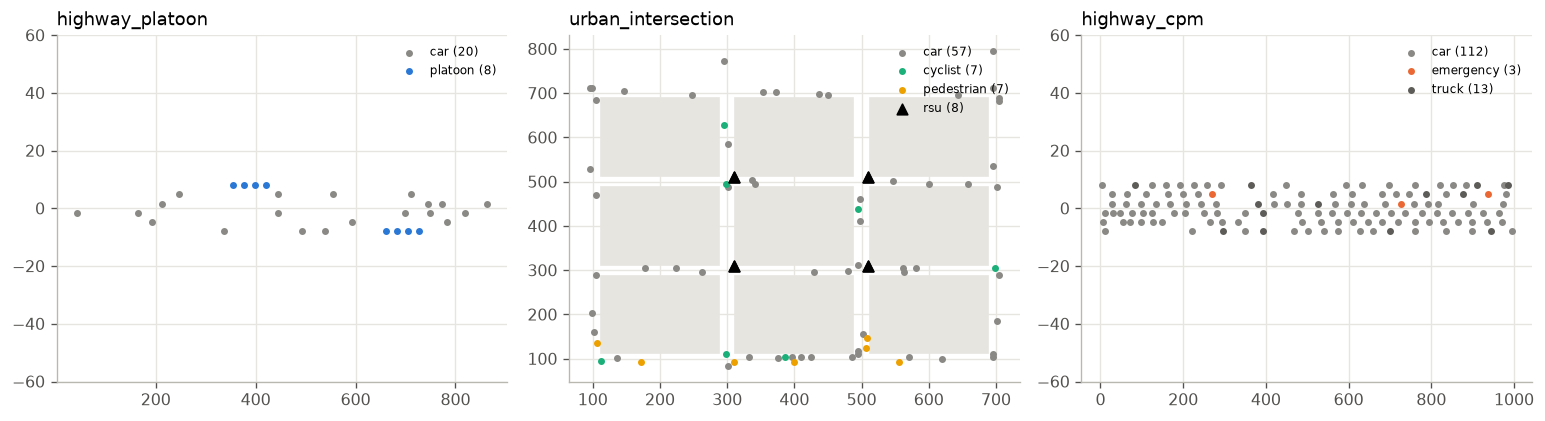

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
colors = {"car": mr.NEUTRAL, "truck": "#5d5c58", "platoon": mr.SERIES_COLORS[0], "emergency": mr.SERIES_COLORS[1],
          "cyclist": mr.SERIES_COLORS[2], "pedestrian": mr.SERIES_COLORS[3], "rsu": "#000000"}
for ax, scenario in zip(axes, ["highway_platoon", "urban_intersection", "highway_cpm"]):
    folder = sorted(d for d in os.listdir(os.path.join(SMOKE, "traces")) if d.startswith(scenario))[0]
    folder = os.path.join(SMOKE, "traces", folder)
    trace = pd.read_csv(os.path.join(folder, "trace.csv")).merge(pd.read_csv(os.path.join(folder, "roles.csv")), on="node_id")
    now = trace[trace.time == trace.time.min()]
    now = pd.concat([now, trace[trace.role == "rsu"].drop_duplicates("node_id")])
    if os.path.exists(os.path.join(folder, "buildings.csv")):
        for corners in pd.read_csv(os.path.join(folder, "buildings.csv")).corners:
            xy = np.array(corners.split(), dtype=float).reshape(-1, 2)
            ax.fill(xy[:, 0], xy[:, 1], color="#e6e5e0", zorder=0)
    for role, group in now.groupby("role"):
        ax.scatter(group.x, group.y, s=10 if role != "rsu" else 40, marker="o" if role != "rsu" else "^",
                   color=colors.get(role, mr.NEUTRAL), label="%s (%d)" % (role, len(group)))
    ax.set_title(scenario)
    ax.legend(fontsize=7, loc="upper right")
    if scenario.startswith("highway"):
        ax.set_ylim(-60, 60)
plt.tight_layout()

## 4. Channel

**Highway** (MoReV2X model, TR 37.885 Table 6.2.1-1): free-space-like LOS pathloss
$PL = 32.4 + 20\log_{10} d + 20\log_{10} f_c$, LOS with the highway LOS probability, otherwise
NLOSv with an extra vehicle-blockage loss of mean $5 + \max(0, 15\log_{10} d - 41)$ dB and σ = 4 dB.
Log-normal shadowing σ = 3 dB, decorrelated over 25 m.

**Urban** (new, branch `feature/urban-channel-tr37885`), TR 37.885 urban grid:

* the straight line between the two UEs crosses a building footprint → **NLOS**,
  $PL = 36.85 + 30\log_{10} d + 18.9\log_{10} f_c$, σ = 4 dB;
* otherwise LOS with probability $\min(1, 1.05\,e^{-0.0114 d})$, $PL = 38.77 + 16.7\log_{10} d + 18.2\log_{10} f_c$
  (UMi street canyon), σ = 3 dB; else **NLOSv**, the same plus the vehicle-blockage loss.
* shadowing decorrelated over 10 m.

Buildings come from the footprints SUMO used (`buildings.csv`). The link state is drawn again every
100 ms, like the highway model.

Text(0.0, 1.0, 'Mean pathloss, 5.9 GHz')

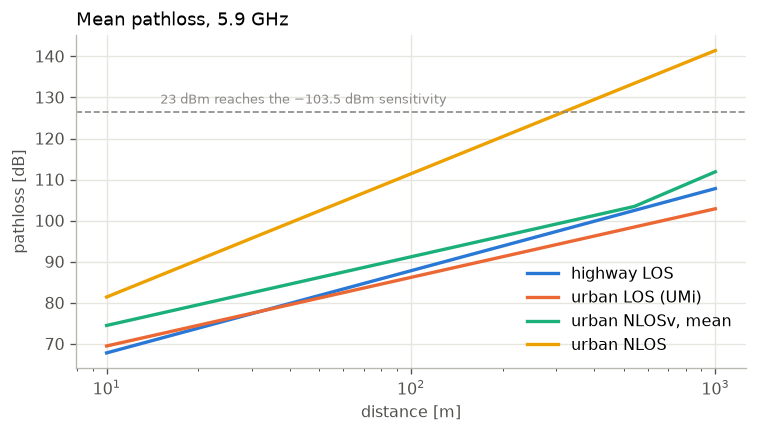

In [5]:
d = np.linspace(10, 1000, 200)
f = 5.9
plt.plot(d, 32.4 + 20 * np.log10(d) + 20 * np.log10(f), label="highway LOS")
plt.plot(d, 38.77 + 16.7 * np.log10(d) + 18.2 * np.log10(f), label="urban LOS (UMi)")
plt.plot(d, 38.77 + 16.7 * np.log10(d) + 18.2 * np.log10(f) + 5 + np.maximum(0, 15 * np.log10(d) - 41), label="urban NLOSv, mean")
plt.plot(d, 36.85 + 30 * np.log10(d) + 18.9 * np.log10(f), label="urban NLOS")
plt.axhline(23 - (-103.5), color=mr.NEUTRAL, ls="--", lw=1)
plt.text(15, 23 + 103.5 + 2, "23 dBm reaches the −103.5 dBm sensitivity", color=mr.NEUTRAL, fontsize=8)
plt.xscale("log"); plt.xlabel("distance [m]"); plt.ylabel("pathloss [dB]"); plt.legend(); plt.title("Mean pathloss, 5.9 GHz")

## 5. Mode 2 mechanisms compared

Three resource selection policies, the same for every class and every UE of a run:

| Policy | Re-evaluation | Pre-emption |
|---|---|---|
| `off` | no | no |
| `reeval` | yes | no |
| `reeval_preempt` | yes | yes |

* **Re-evaluation** (TS 38.214 §8.1.4, re-evaluation of resources not yet signalled): at T3 = T_proc,1
  (9 slots at μ = 2) before a selected resource that no SCI has announced yet, the UE runs steps 1–7
  again. If the resource is no longer in the candidate set, it selects another one. MoReV2X already
  had it. Announced resources (the next SPS period, an announced retransmission) are not re-evaluated.
* **Pre-emption** (TS 38.321 §5.22.1.1, new): at T3 before an **announced** resource, the UE checks
  the reservations it sensed. If one of priority $p_{rx}$ lower than its own $p_{tx}$ (more important),
  with RSRP above $Th(p_{rx}, p_{tx})$ after the 3 dB steps of the procedure, covers the resource
  or one of its next periods (step 6 c, $j < C_{resel}$), the resource is pre-empted and re-selected. `PreemptionPriority` (sl-PreemptionEnable) can limit
  it to priorities below a level; the sweep uses 0, any higher priority.
* **Priority-aware sensing** is implemented too (`--PriorityAware`): $Th(p_{rx}, p_{tx}) = Th_0 + 3\,(p_{rx} - p_{tx})$ dB
  or a full 64-entry sl-ThresRSRP-List, and X % per priority. The main sweep keeps one threshold so
  that only re-evaluation and pre-emption differ between policies; add `PriorityAware: 1` to a
  policy to study it.

**Several flows per UE** (new): each class is its own multicast group, hence its own sidelink
logical channel and its own Mode 2 process (SPS or dynamic, own RRI, own counter). In each slot the
flows are served in priority order. A UE sends one PSSCH per slot: when two flows hold the same
slot, the more important one transmits and the other's packet is dropped (`intra-UE conflict`).
To make that rare, each flow leaves out of its candidates every slot the UE's other flows reserved,
over all the periods they keep their reservations.

**SPS or dynamic per class.** SPS classes reserve with their RRI for Cresel periods (5–15 at 100 ms,
scaled for shorter RRIs). Dynamic classes select for each packet and announce nothing ahead.
In `highway_cpm` the CPM class is compared three ways: SPS reserving for the largest CPM
(`sps_max`), SPS reserving for the median (`sps_median`, larger CPMs trigger size reselections), and
dynamic, a new selection for every CPM (`dynamic`, the aggressive reselection case).

## 6. Injected impairments (highway platoon)

| Condition | What | Model |
|---|---|---|
| `baseline` | nothing | |
| `jamming` | wideband jammer 25 m off the road at mid-highway, 23 dBm over the 24 RBs, on 30 % of every 10 ms, from 5 to 12 s | ns-3 `WaveformGenerator` on the sidelink channel. The NR PHY adds any non-sidelink signal to the interference of the TBs it overlaps |
| `loss_bursts` | burst losses at the platoon trucks | Gilbert-Elliott per receiver: good periods of mean 0.5 s, bad periods of mean 50 ms, exponential lengths. In a bad period every TB is lost, SCI included, so sensing also misses it. Logged with `lossType` 4 |
| `stack_latency` | higher-layer latency of platooning messages | 3 ms + Uniform(0, 4) ms between generation and the sidelink, the generation time stays the original one, so the remaining budget shrinks |

The jammer raises interference, not the CBR: MoReV2X measures CBR from received sidelink signals.

## 7. Metrics

All metrics are per class, per scenario and per condition, and most per Tx-Rx distance bin of 50 m
up to 1000 m. The first 3 s of each run are left out. `tools/qos/metrics.py` computes them from the
MoReV2X logs, the application log of `QOS` and the trace.

**Attempt.** A packet generated by node *i* and a node *j* active within 1000 m of *i* at the
generation time. Packets the MAC never sent are attempts too, so drops count as failures. This is
the denominator of every rate below.

| Metric | Definition |
|---|---|
| **PDR** | attempts with at least one copy decoded / attempts |
| **QoS-PDR** | attempts decoded within the PDB of the class / attempts. *1 − QoS-PDR* is the measured PER, compared with the PER of the PQI (`per_met`). The PDB has one slot (0.25 ms) of tolerance: the selection window ends with the slot that contains generation + PDB, and a reception is complete at the end of its slot |
| **PIR** | packet inter-reception time: time between two consecutive decoded packets of one class from *i* at *j* |
| **DT** | disconnection time (Rolich, Yildiz, Baiocchi, *IEEE Commun. Lett.* 2026): a PIR interval that contains at least one lost attempt of that pair. Mean DT, quantiles, and how many. PIR counts every interval, DT only the ones that hide a loss, so DT shows how long the receiver was blind when it was blind |
| **AoI** | age of information, time average of the age of the freshest decoded packet of the class at *j*: area under the sawtooth between receptions over the time spanned, plus the peak AoI. Meaningful for the regular classes; for event-driven ones (crash mitigation) it mostly measures the time between events |
| **latency** | p50 and p99 of decoded packets, generation to reception |
| **collision rate** | attempts lost with `lossType` 3 (another sidelink TB overlapped in time and frequency and the SINR failed) / attempts |
| **CBR** | channel busy ratio measured by every UE (S-RSSI above −88 dBm per subchannel over 100 ms), mean and p95 |
| **channel occupancy** | subchannel-slots used by the class / subchannel-slots of the channel, and the mean per-UE share (CR) |
| **re-evaluations, pre-emptions** | checks run and resources changed, per class (priority) |
| **root cause** | one cause per failed attempt, list below |
| **HNIR, HNCR** | hidden-node metrics, below |

**Root causes** (in order of precedence):

| Cause | Meaning |
|---|---|
| decoded in time | not a failure, counted to close the sum |
| late | decoded after the PDB |
| oversize drop | larger than a slot, dropped by the MAC |
| intra-UE conflict | lost its slot to a more important flow of the same UE |
| replaced by a newer packet | a newer packet of the class arrived before it was sent |
| never transmitted | still queued or expired in the MAC when the run ended |
| half duplex | *j* was transmitting in that slot |
| below sensitivity | received power under −103.5 dBm |
| propagation | above sensitivity but the SINR failed with no overlapping TB: fading, NLOS, the jammer |
| hidden-node collision | overlapped by TBs whose senders were **all hidden** from *i* |
| sensing-visible collision | overlapped by at least one TB *i* could have sensed: simultaneous selections, unannounced (dynamic) packets, re-evaluation too late, the threshold raised by the 3 dB steps |
| injected burst | lost to the Gilbert-Elliott burst model |

**Hidden-node metric (new).** For a collided attempt the interferers are the other transmissions in
the same slot overlapping its RBs (`phyDebugShort.txt`). An interferer *k* is **hidden** from the
sender *i* if *i* decoded none of *k*'s packets in the 1.1 s before: *i* could not have sensed *k*'s
reservations, whatever its threshold. Then

$$\text{HNCR} = \frac{\#\text{ hidden-node collisions}}{\#\text{ collisions}},\qquad
\text{HNIR} = \frac{\#\text{ hidden-node collisions}}{\#\text{ attempts}}.$$

HNCR says what share of the collisions sensing could never prevent. HNIR is the PDR lost to hidden
nodes: no Mode 2 sensing improvement can recover more than HNIR, while the sensing-visible
collisions are what re-evaluation, pre-emption and thresholds can act on.

## 8. One smoke run, all the outputs

In [6]:
run_id = sorted(r for r in os.listdir(os.path.join(SMOKE, "runs")) if r.startswith("highway_platoon") and "baseline" in r)[0]
metrics_folder = os.path.join(SMOKE, "runs", run_id, "metrics")
print(run_id)
print(open(os.path.join(SMOKE, "runs", run_id, "command.txt")).read())
pd.read_csv(os.path.join(metrics_folder, "flows.csv"))[
    ["name", "pqi", "priority", "attempts", "pdr", "qos_pdr", "per_measured", "per_target", "collision_rate",
     "hnir", "pir_mean_ms", "dt_mean_ms", "aoi_mean_ms", "occupancy", "cbr_mean"]].round(4)

highway_platoon_low_baseline_default_off_s1
/Users/hadih/Documents/MoReV2X-hadih/build/optimized/scratch/QOS --trace=/Users/hadih/Documents/MoReV2X-hadih/results/qos/qos_smoke/traces/highway_platoon_low_1 --flows=/Users/hadih/Documents/MoReV2X-hadih/results/qos/qos_smoke/flows/highway_platoon_baseline_default.csv --out=/Users/hadih/Documents/MoReV2X-hadih/results/qos/qos_smoke/runs/highway_platoon_low_baseline_default_off_s1/logs/ --simTime=4 --seed=1 --runNo=1 --Numerology=2 --ChannelBW=20 --SubChannel=12 --mcs=14 --ueTxPower=23 --RSRP=-128 --SavingPeriod=0.5 --ReEvaluation=0 --Preemption=0 --ns3::NrV2XSpectrumPhy::MetricsMaxDistance=1000



,name,pqi,priority,attempts,pdr,qos_pdr,per_measured,per_target,collision_rate,hnir,pir_mean_ms,dt_mean_ms,aoi_mean_ms,occupancy,cbr_mean
0,platooning,21,3,33830,0.9888,0.9888,0.0112,0.0001,0.0000,0.0,20.1334,68.7934,20.3829,0.2004,0.3092
1,advanced_driving,22,4,5580,0.9631,0.9631,0.0369,0.0100,0.0038,0.0,102.9841,244.7755,80.4160,0.0165,0.3092
2,cooperative_perception,23,6,8222,0.7755,0.7755,0.2245,0.0100,0.0197,0.0,128.4048,161.8890,120.7123,0.0206,0.3092
3,cam,90,5,26456,0.9785,0.9785,0.0215,0.0001,0.0005,0.0,101.7008,226.0199,102.1681,0.1558,0.3092
4,crash_mitigation,91,1,305,0.9607,0.9607,0.0393,0.0000,0.0000,0.0,10.0075,18.5000,6.1748,0.0019,0.3092


Files a run keeps after its raw logs are deleted:

In [7]:
pd.DataFrame({"file": sorted(os.listdir(metrics_folder))}).assign(
    rows=lambda t: [sum(1 for _ in open(os.path.join(metrics_folder, f))) if f.endswith(".csv") else "" for f in t.file])

,file,rows
0,aoi_pairs.csv,2062
1,by_distance.csv,97
2,causes.csv,230
3,cbr_time.csv,18
4,flows.csv,6
5,histograms.csv,226
6,params.json,
7,run.json,


## 9. The sweep

`scenarios/qos/sweep_full.yaml` lists every run: scenarios × densities × conditions × variants ×
policies × seeds. `classes.yaml` holds the classes. A key under a condition or variant changes the
QOS arguments (`arguments:`) or a class (`classes:`).

In [8]:
runs = sweep.expand(full)
table = pd.DataFrame([{k: v for k, v in r.items() if not k.endswith("_spec")} for r in runs])
print(len(table), "runs")
table.groupby(["scenario", "density", "condition", "variant"]).size().unstack(fill_value=0)

144 runs


variant                                   default  dynamic  sps_max  sps_median
scenario           density condition                                           
highway_cpm        high    baseline             0        9        9           9
                   medium  baseline             0        9        9           9
highway_platoon    high    baseline             9        0        0           0
                           jamming              9        0        0           0
                           loss_bursts          9        0        0           0
                           stack_latency        9        0        0           0
                   low     baseline             9        0        0           0
                           jamming              9        0        0           0
                           loss_bursts          9        0        0           0
                           stack_latency        9        0        0           0
urban_intersection high    baseline             9        0        0           0
                   low     baseline             9        0        0           0

**Budget.** The sweep is sized for about 8 hours on 30 parallel jobs. The time of a run grows with
the number of nodes and the packet rate, the smoke runs below give the rate on this machine.

In [9]:
smoke_runs = pd.read_csv(os.path.join(SMOKE, "summary", "runs.csv"))
smoke_runs[["id", "seconds"]].sort_values("seconds", ascending=False).head(8)

,id,seconds
1,highway_cpm_medium_baseline_sps_max_reeval_preempt_s1,105.2
2,highway_cpm_medium_baseline_sps_median_reeval_preempt_s1,105.2
0,highway_cpm_medium_baseline_dynamic_reeval_preempt_s1,93.6
4,highway_platoon_low_baseline_default_reeval_preempt_s1,22.3
16,urban_intersection_low_baseline_default_reeval_preempt_s1,19.8
15,urban_intersection_low_baseline_default_off_s1,17.3
17,urban_intersection_low_baseline_default_reeval_s1,16.4
7,highway_platoon_low_jamming_default_reeval_preempt_s1,16.2


**Launch it** on the Ubuntu host (32 cores, 128 GB), everything in Docker. Commands also in
`COMMANDS.txt`, section QOS:

```bash
cd ~/Documents && git clone git@github.com:0had0/MoReV2X.git MoReV2X-hadih
cd MoReV2X-hadih && git checkout feature/qos-evaluation
tools/qos/remote/launch.sh scenarios/qos/sweep_smoke.yaml 8      # 10 min check first
tools/qos/remote/launch.sh                                        # the full sweep, detached tmux session "qos"
tools/qos/remote/monitor.sh                                       # tmux session "qos-monitor": progress, log, load
```

Then, on this machine:

```bash
tools/qos/remote/download.sh user@host qos_full
```

The sweep resumes where it stopped if launched again, and a failed run is retried. The raw logs of
a run are deleted once its metrics are written (`keep_raw: true` keeps them, about 0.3 GB a run).

## 10. Limitations

* SL priorities of the classes are an assumption (section 2).
* Blind retransmissions only, no HARQ feedback: 1 for the 10⁻⁴ classes (platooning, emergency
  trajectory, CAM, VAM), 2 for crash mitigation. Each packet carries its count in the V2X tag
  (`TxPerTb`), so classes of one UE differ. All copies sit within 32 slots of each other. The SCI
  of a copy announces the next one only, as MoReV2X always did, not both.
* Crash mitigation has a 3 ms PDB: 10 candidate slots, and after the 20 % rule of step 6 the
  candidates sometimes lie on two slots only, so a few of its packets get 2 copies instead of 3.
* Pre-emption needs the higher-priority reservation to be in an SCI first. SPS classes announce
  their next period; dynamic classes only announce their next copy, so crash mitigation and
  emergency trajectory pre-empt only through their retransmissions, within 32 slots.
* C_resel: MoReV2X projects reservations over SL_RESOURCE_RESELECTION_COUNTER periods, where
  TS 38.214 8.1.5 uses 10 times the counter. This is the original MoReV2X model and applies to
  every policy alike.
* The jammer raises interference but not the measured CBR.
* Packets above 637 B payload do not fit one slot and are not segmented; a packet still waiting
  when the next one of its class arrives is replaced.
* String stability (closed-loop platoon control) is not modelled: tracked as a GitHub task.